# Phase 4: Feature Engineering (TF-IDF)

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
sys.path.insert(0, str(PROJECT_ROOT))

from src.features import (
    NEWS_CONFIG,
    SMS_CONFIG,
    TfidfConfig,
    build_vectorizer,
    fit_transform_split,
    matrix_stats,
    top_terms,
)
from src.utils import PROCESSED_DATA_DIR, load_csv

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

## Step 1: Load the cleaned datasets

In [3]:
news = load_csv(PROCESSED_DATA_DIR / "news_clean.csv")
sms = load_csv(PROCESSED_DATA_DIR / "sms_clean.csv")
print("News:", news.shape, news["label"].value_counts().to_dict())
print("SMS: ", sms.shape, sms["label"].value_counts().to_dict())

News: (39075, 2) {'real': 21175, 'fake': 17900}
SMS:  (5124, 2) {'ham': 4498, 'spam': 626}


## Step 2: Watch the vocabulary grow with n-grams

In [4]:
rows = []
for ngram in [(1, 1), (1, 2)]:
    vec = build_vectorizer(TfidfConfig(max_features=None, ngram_range=ngram, min_df=3, max_df=0.9))
    X = vec.fit_transform(news["text"])
    rows.append({"ngram_range": str(ngram), **matrix_stats(X)})

pd.DataFrame(rows)

,ngram_range,documents,features,non_zero_entries,density,avg_terms_per_document
0,"(1, 1)",39075,48749,7951473,0.004174,203.492591
1,"(1, 2)",39075,639441,19363820,0.000775,495.555214


## Step 3: Leakage, shown directly

In [5]:
news_split = fit_transform_split(news, NEWS_CONFIG, positive_label="fake", negative_label="real")

vec_all = build_vectorizer(NEWS_CONFIG).fit(news["text"])
vocab_all = set(vec_all.get_feature_names_out())
vocab_train_only = set(news_split.vectorizer.get_feature_names_out())

print("Vocabulary fitted on ALL rows:  ", len(vocab_all))
print("Vocabulary fitted on TRAIN only:", len(vocab_train_only))
print("Terms that only the test set would have contributed:", len(vocab_all - vocab_train_only))

Vocabulary fitted on ALL rows:   50000
Vocabulary fitted on TRAIN only: 50000
Terms that only the test set would have contributed: 1420


## Step 4: Build the news feature matrices (leakage-safe)

The vectorizer is fitted on training rows only, and the test rows are
transformed with the training vocabulary.

In [6]:
print("X_train:", news_split.X_train.shape, "| y_train counts:", pd.Series(news_split.y_train).value_counts().to_dict())
print("X_test: ", news_split.X_test.shape, "| y_test counts: ", pd.Series(news_split.y_test).value_counts().to_dict())
print()
print("Training matrix stats:", matrix_stats(news_split.X_train))

X_train: (31260, 50000) | y_train counts: {0: 16940, 1: 14320}
X_test:  (7815, 50000) | y_test counts:  {0: 4235, 1: 3580}

Training matrix stats: {'documents': 31260, 'features': 50000, 'non_zero_entries': 11569432, 'density': 0.0074020678182981445, 'avg_terms_per_document': 370.1033909149072}


## Step 5: Look at the most influential terms

In [7]:
top_terms(news_split.vectorizer, news_split.X_train, n=20)

,term,total_tfidf
0,that,698.378
1,for,637.383
2,trump,630.334
3,is,611.316
4,said,609.629
5,he,566.371
6,it,552.695
7,with,541.884
8,was,519.526
9,as,502.548


## Step 6: Build the SMS feature matrices 

In [8]:
sms_split = fit_transform_split(sms, SMS_CONFIG, positive_label="spam", negative_label="ham")

print("X_train:", sms_split.X_train.shape, "| y_train counts:", pd.Series(sms_split.y_train).value_counts().to_dict())
print("X_test: ", sms_split.X_test.shape, "| y_test counts: ", pd.Series(sms_split.y_test).value_counts().to_dict())
print()
print("SMS training matrix stats:", matrix_stats(sms_split.X_train))
print()
top_terms(sms_split.vectorizer, sms_split.X_train, n=20)

X_train: (4099, 9783) | y_train counts: {0: 3598, 1: 501}
X_test:  (1025, 9783) | y_test counts:  {0: 900, 1: 125}

SMS training matrix stats: {'documents': 4099, 'features': 9783, 'non_zero_entries': 74165, 'density': 0.0018494774019995803, 'avg_terms_per_document': 18.093437423761895}



,term,total_tfidf
0,you,124.219
1,to,112.083
2,the,86.046
3,in,71.423
4,and,68.501
5,me,65.505
6,is,64.899
7,my,57.806
8,for,55.482
9,your,51.867


## Step 7: Compare the two feature spaces

dataset  avg_terms_per_document  features
   news                  370.10     50000
    sms                   18.09      9783


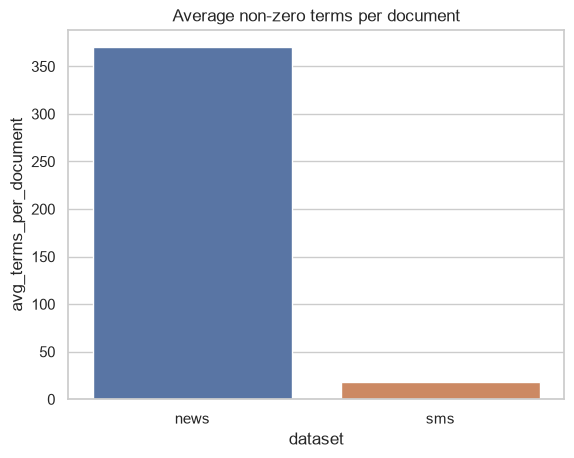

In [9]:
comparison = pd.DataFrame({
    "dataset": ["news", "sms"],
    "avg_terms_per_document": [
        matrix_stats(news_split.X_train)["avg_terms_per_document"],
        matrix_stats(sms_split.X_train)["avg_terms_per_document"],
    ],
    "features": [news_split.X_train.shape[1], sms_split.X_train.shape[1]],
})
print(comparison.round(2).to_string(index=False))

sns.barplot(data=comparison, x="dataset", y="avg_terms_per_document", hue="dataset", legend=False)
plt.title("Average non-zero terms per document")
plt.show()